<a href="https://colab.research.google.com/github/Just-polite/4IK25CS187_DAV_LAB/blob/main/4IK25CS187_EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 11: Hierarchial Clustering: Building dendogram and applying agglomerative clustering

In [1]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram,linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

Load dataset and select features

In [2]:
df=pd.read_csv("/content/House_Price_dataset.csv")
df=df[df['purpose']=='For Sale']
df=df[['price','bedrooms','baths','Area Size']].dropna()


Clean data: remove zero values and extreme outliers

In [3]:
df=df[(df['bedrooms'] >0) & (df['baths']>0)]
df=df[df['price']<df['price'].quantile(0.99)]
df=df[df['Area Size']<df['Area Size'].quantile(0.99)]

Take a small sample (dataset is very large , dendrogram needs few rows

In [4]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

Scale the features

In [5]:
X=df[['price','bedrooms','baths','Area Size']]
X_scaled=StandardScaler().fit_transform(X)


Build and plot the dendrogram

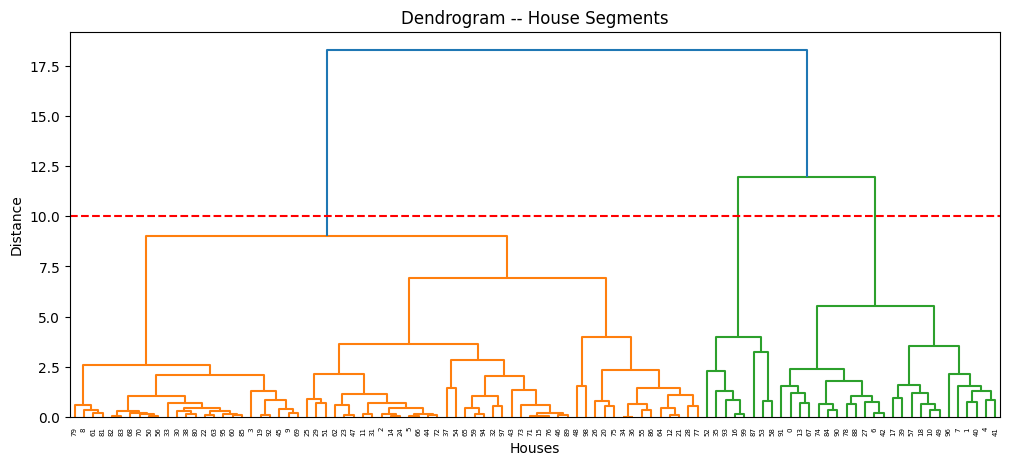

In [6]:
linked=linkage(X_scaled,method='ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel('Houses')
plt.ylabel('Distance')
plt.axhline(y=10,color='red',linestyle='--')
plt.show()

Fit Agglomerative Clustering using the chosen cut

In [7]:
hc=AgglomerativeClustering(n_clusters=3,linkage='ward')
df['HC_Cluster']=hc.fit_predict(X_scaled)

Cluster Summary

In [8]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
0    68
1    24
2     8
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           10905838.24      2.69   2.75       5.16
1           18070833.33      5.54   6.12       7.96
2           57562500.00      5.50   6.62       1.14


plot the clusters

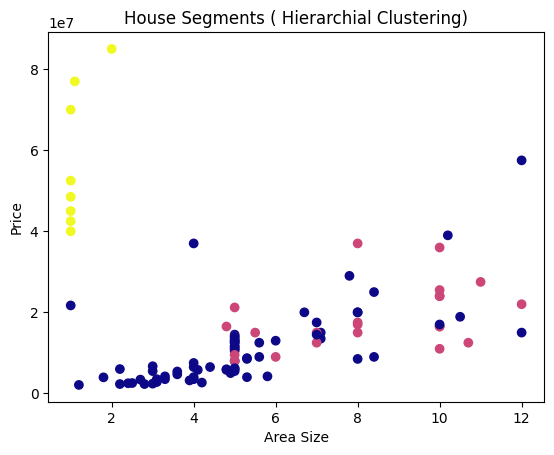

In [9]:
plt.scatter(df['Area Size'],df['price'],c=df['HC_Cluster'],cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments ( Hierarchial Clustering)')
plt.show()